In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


df = pd.read_csv("./data/AAPL.csv")

df["Date"] = pd.to_datetime(df["Date"])

df.set_index("Date", inplace=True)

df['Adj Close'] = pd.to_numeric(df['Adj Close'], errors='coerce')


df['future_return'] = (df['Adj Close'].shift(-1) - df['Adj Close']) / df['Adj Close']
# df["future_return"] = df["Adj Close"].pct_change().shift(-1)

df.dropna(subset=['future_return'], inplace=True)
print(df.head())

                Open      High       Low     Close  Adj Close       Volume  \
Date                                                                         
1980-12-12  0.128348  0.128906  0.128348  0.128348   0.101073  469033600.0   
1980-12-15  0.122210  0.122210  0.121652  0.121652   0.095800  175884800.0   
1980-12-16  0.113281  0.113281  0.112723  0.112723   0.088768  105728000.0   
1980-12-17  0.115513  0.116071  0.115513  0.115513   0.090965   86441600.0   
1980-12-18  0.118862  0.119420  0.118862  0.118862   0.093603   73449600.0   

            future_return  
Date                       
1980-12-12      -0.052170  
1980-12-15      -0.073403  
1980-12-16       0.024750  
1980-12-17       0.029000  
1980-12-18       0.061024  


In [3]:
df["signal"] = np.random.choice([0, 1], size=len(df), p=[0.5, 0.5])

print(df["signal"])
print(df['signal'].value_counts(normalize=True))

Date
1980-12-12    0
1980-12-15    0
1980-12-16    0
1980-12-17    0
1980-12-18    0
             ..
2021-01-22    0
2021-01-25    0
2021-01-26    1
2021-01-27    1
2021-01-28    0
Name: signal, Length: 10116, dtype: int64
signal
1    0.507908
0    0.492092
Name: proportion, dtype: float64


In [4]:
df["pnl"] = df["signal"] * df["future_return"]

In [5]:
total_earned = df["pnl"].sum()
total_invested = df["signal"].sum()

strategy_return = total_earned / total_invested

print(strategy_return)

0.0007521150925501652


In [6]:
df["always_buy"] = df["future_return"]

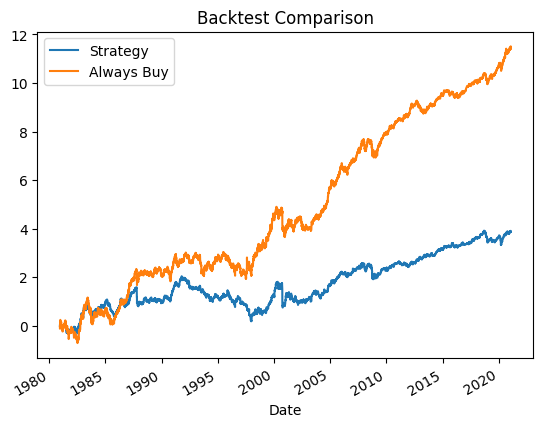

In [11]:
plt.figure()

df['pnl'].cumsum().plot(label='Strategy')
df['always_buy'].cumsum().plot(label='Always Buy')
plt.legend()
plt.title('Backtest Comparison')
plt.show()